# 🧹 Cleaning a Real-World Kaggle Dataset — Missing Values & Outliers

**Dataset:** Titanic passenger data (Kaggle *Titanic – Machine Learning from Disaster*, `train.csv`, 891 passengers).
It is a genuinely messy real-world table: ~20% missing ages, 77% missing cabins, 2 missing ports and a heavily skewed `Fare`.

**Task steps**
1. Download dataset and load into DataFrame
2. Analyze missing patterns and decide imputation strategy
3. Apply IQR method to detect outliers
4. Remove or cap outliers
5. Export cleaned data

## Step 1 — Download the dataset & load into a DataFrame

**Getting the data from Kaggle** (one-time, outside the notebook):
```bash
pip install kaggle                       # then place kaggle.json in ~/.kaggle/
kaggle competitions download -c titanic  # or download train.csv manually from kaggle.com/c/titanic
```
Put `train.csv` at `data/raw/titanic.csv`. A copy is already bundled in this project, so the notebook runs out of the box.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (10, 5), "axes.grid": True, "grid.alpha": .25,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 11})

ROOT = Path("..") if Path("../data").exists() else Path(".")
RAW_PATH = ROOT / "data/raw/titanic.csv"
OUT_DIR = ROOT / "data/cleaned"
IMG_DIR = ROOT / "images"
for d in (OUT_DIR, IMG_DIR): d.mkdir(parents=True, exist_ok=True)

def save_fig(name):
    plt.tight_layout(); plt.savefig(IMG_DIR / f"{name}.png", dpi=150, bbox_inches="tight"); plt.show()

In [2]:
raw = pd.read_csv(RAW_PATH)
df = raw.copy()                       # work on a copy, keep `raw` untouched for before/after comparison
print(f"Loaded {df.shape[0]} rows x {df.shape[1]} columns")
df.head()

Loaded 891 rows x 12 columns


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.00,1,0,A/5 21171,7.25,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.00,1,0,PC 17599,71.28,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.00,0,0,STON/O2. 3101282,7.92,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.00,1,0,113803,53.10,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.00,0,0,373450,8.05,NaN,S


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [4]:
print("Duplicate rows:", df.duplicated().sum())
df.describe(include="all").T

Duplicate rows: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
PassengerId,891.00,NaN,NaN,NaN,446.00,257.35,1.00,223.50,446.00,668.50,891.00
Survived,891.00,NaN,NaN,NaN,0.38,0.49,0.00,0.00,0.00,1.00,1.00
Pclass,891.00,NaN,NaN,NaN,2.31,0.84,1.00,2.00,3.00,3.00,3.00
Name,891,891,"Braund, Mr. Owen Harris",1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sex,891,2,male,577,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,714.00,NaN,NaN,NaN,29.70,14.53,0.42,20.12,28.00,38.00,80.00
SibSp,891.00,NaN,NaN,NaN,0.52,1.10,0.00,0.00,0.00,1.00,8.00
Parch,891.00,NaN,NaN,NaN,0.38,0.81,0.00,0.00,0.00,0.00,6.00
Ticket,891,681,347082,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fare,891.00,NaN,NaN,NaN,32.20,49.69,0.00,7.91,14.45,31.00,512.33


## Step 2 — Analyze missing patterns & decide imputation strategy

### 2.1 How much is missing, and where?

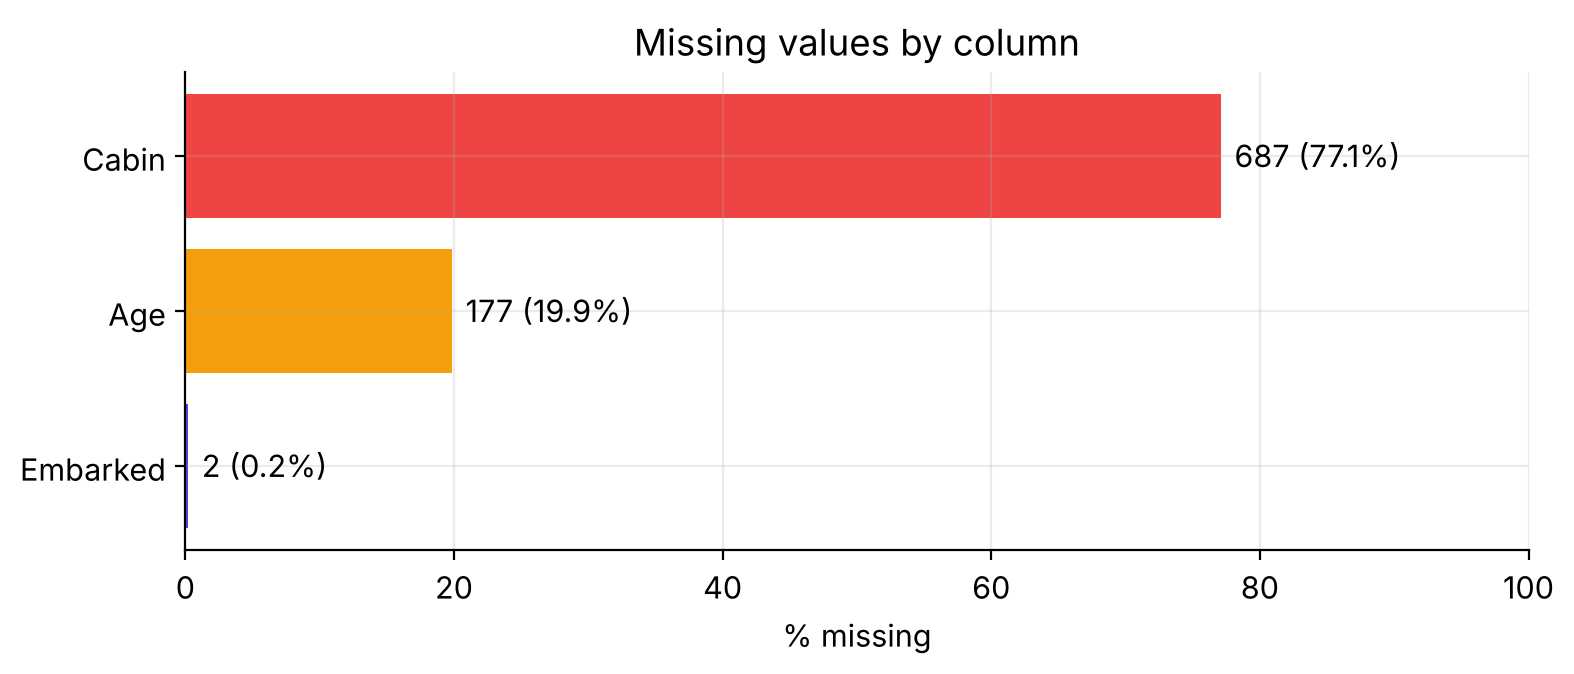

,missing,missing_%
Cabin,687,77.10
Age,177,19.87
Embarked,2,0.22


In [5]:
miss = pd.DataFrame({"missing": df.isna().sum(), "missing_%": df.isna().mean() * 100})
miss = miss[miss.missing > 0].sort_values("missing", ascending=False)

fig, ax = plt.subplots(figsize=(8, 3.5))
bars = ax.barh(miss.index[::-1], miss["missing_%"][::-1], color=["#4F46E5", "#F59E0B", "#EF4444"])
for b, (n, p) in zip(bars, zip(miss["missing"][::-1], miss["missing_%"][::-1])):
    ax.text(b.get_width() + 1, b.get_y() + b.get_height() / 2, f"{n} ({p:.1f}%)", va="center")
ax.set_xlim(0, 100); ax.set_xlabel("% missing"); ax.set_title("Missing values by column")
save_fig("01_missing_overview")
miss

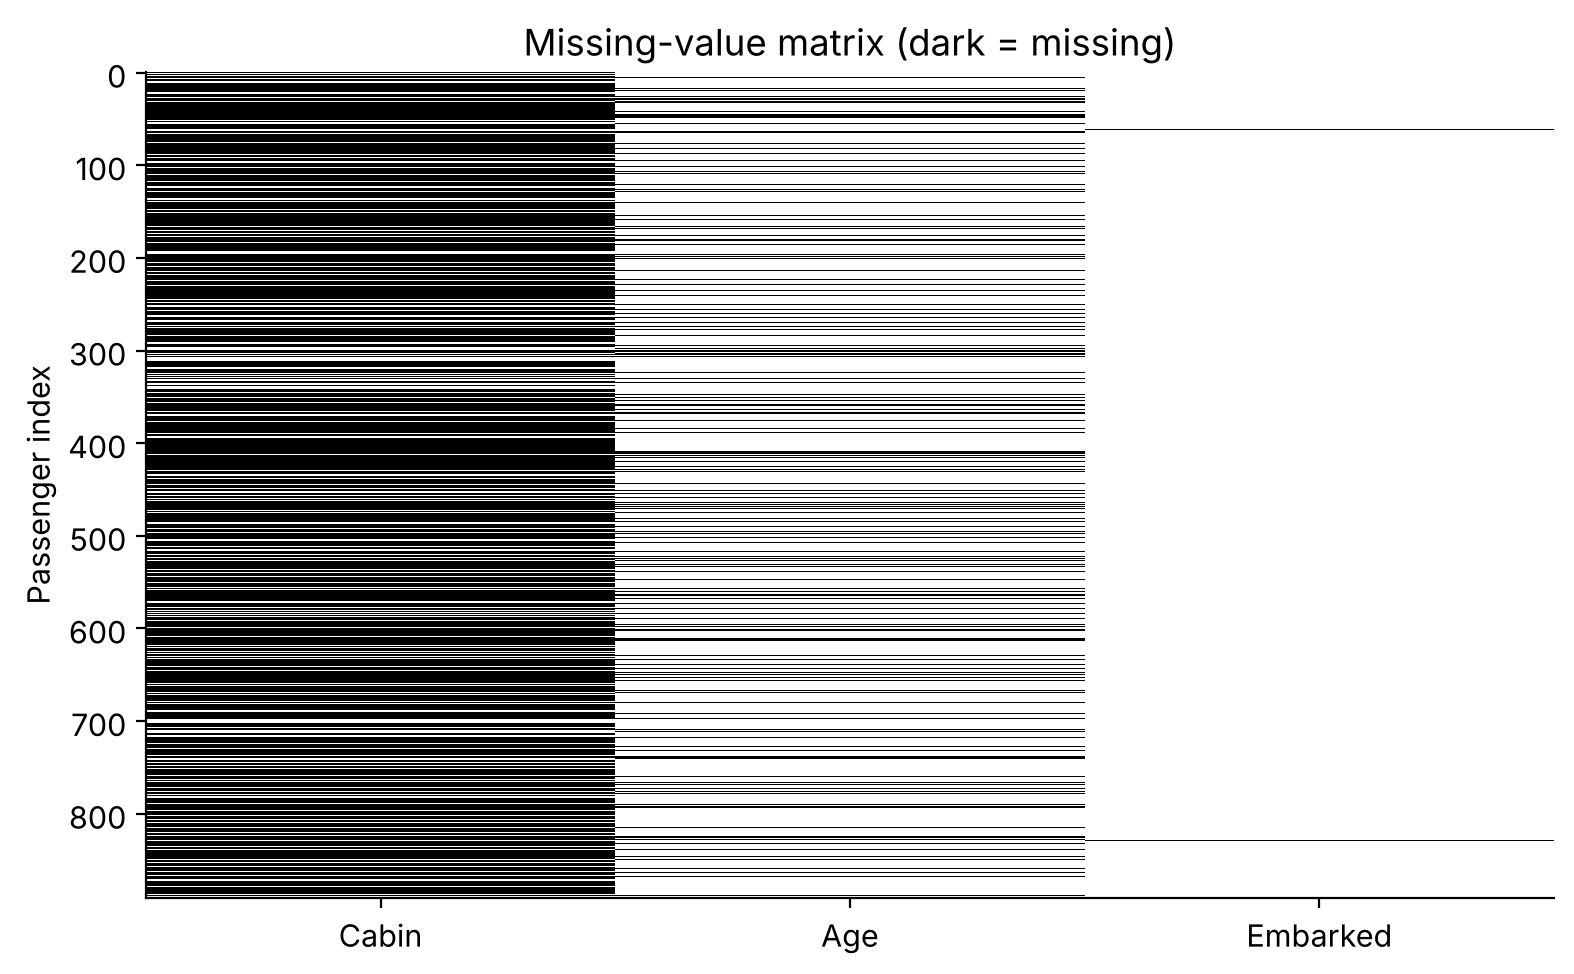

In [6]:
# Missingness "matrix": each row is a passenger, dark = missing
cols = miss.index.tolist()
fig, ax = plt.subplots(figsize=(8, 5))
ax.imshow(df[cols].isna().values, aspect="auto", cmap="Greys", interpolation="nearest")
ax.set_xticks(range(len(cols)), cols); ax.set_ylabel("Passenger index"); ax.grid(False)
ax.set_title("Missing-value matrix (dark = missing)")
save_fig("02_missing_matrix")

### 2.2 Is the missingness random? (MCAR / MAR / MNAR check)

In [7]:
age_na = df["Age"].isna()
print("Missing Age rate by passenger class:")
print((age_na.groupby(df["Pclass"]).mean() * 100).round(1).to_string(), "\n")
print("Missing Age rate by sex:")
print((age_na.groupby(df["Sex"]).mean() * 100).round(1).to_string(), "\n")

print("Survival rate  | Age missing vs present:")
print((df.groupby(age_na)["Survived"].mean() * 100).round(1).rename({False: "present", True: "missing"}).to_string(), "\n")
print("Survival rate  | Cabin recorded vs missing:")
print((df.groupby(df["Cabin"].notna())["Survived"].mean() * 100).round(1).rename({False: "no cabin", True: "has cabin"}).to_string(), "\n")
print("Rows with missing Embarked:")
df[df["Embarked"].isna()][["Name", "Pclass", "Fare", "Sex"]]

Missing Age rate by passenger class:
Pclass
1   13.90
2    6.00
3   27.70 

Missing Age rate by sex:
Sex
female   16.90
male     21.50 

Survival rate  | Age missing vs present:
Age
present   40.60
missing   29.40 

Survival rate  | Cabin recorded vs missing:
Cabin
no cabin    30.00
has cabin   66.70 

Rows with missing Embarked:


,Name,Pclass,Fare,Sex
61,"Icard, Miss. Amelie",1,80.00,female
829,"Stone, Mrs. George Nelson (Martha Evelyn)",1,80.00,female


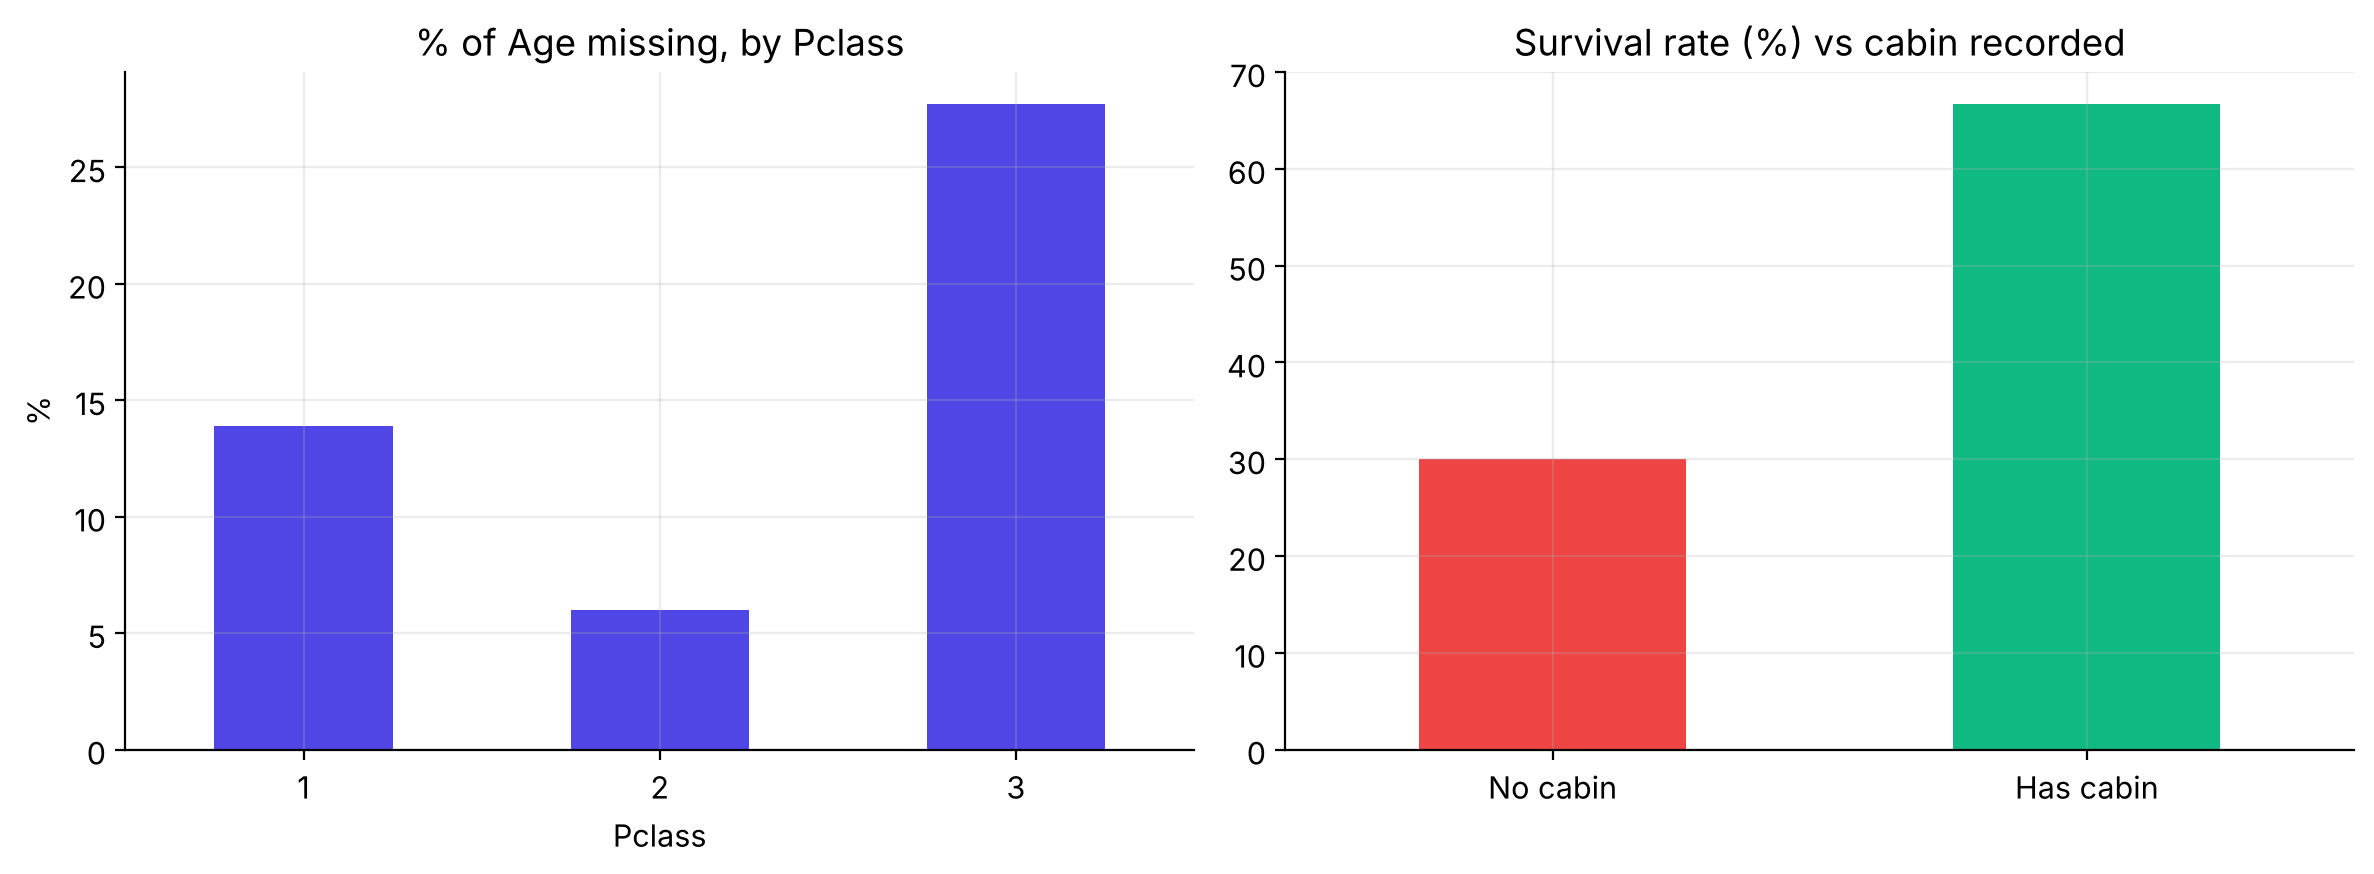

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
(age_na.groupby(df["Pclass"]).mean() * 100).plot.bar(ax=axes[0], color="#4F46E5", rot=0)
axes[0].set_title("% of Age missing, by Pclass"); axes[0].set_ylabel("%")
df.groupby(df["Cabin"].notna())["Survived"].mean().mul(100).rename({False: "No cabin", True: "Has cabin"}) \
  .plot.bar(ax=axes[1], color=["#EF4444", "#10B981"], rot=0)
axes[1].set_title("Survival rate (%) vs cabin recorded"); axes[1].set_xlabel("")
save_fig("03_missing_patterns")

### 2.3 Findings & imputation strategy

| Column | Missing | Pattern | Decision | Why |
|---|---|---|---|---|
| **Age** | 177 (19.9%) | **MAR** – depends on class (3rd class ≈ 28% missing vs 1st ≈ 14%) | Impute with **median of Title × Pclass group** | Age differs strongly by title (Master ≈ 3.5 y, Mrs ≈ 35 y) and class; a global mean would blur this and flatten the distribution |
| **Cabin** | 687 (77.1%) | **MNAR** – a cabin was mostly recorded for survivors / 1st class | **Drop column, keep `Has_Cabin` flag** | Too sparse to impute credibly, but *having* a cabin is informative (≈ 67% vs 30% survival) |
| **Embarked** | 2 (0.2%) | Negligible | Impute with **mode** | Two rows only; both 1st-class women – mode (Southampton) is the safe choice |

Median (not mean) is used because Age is slightly skewed and the median is robust to the very outliers we handle in Step 3.

In [9]:
# Feature engineering needed for the imputation + keep the informative signal from Cabin
df["Has_Cabin"] = df["Cabin"].notna().astype(int)

df["Title"] = df["Name"].str.extract(r",\s*([^\.]+)\.", expand=False).str.strip()
df["Title"] = df["Title"].replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"})
rare = df["Title"].value_counts()[lambda s: s < 10].index           # Dr, Rev, Col, Major, ...
df["Title"] = df["Title"].replace(dict.fromkeys(rare, "Rare"))

print(df.groupby("Title")["Age"].agg(count="count", median="median").round(1))

        count  median
Title                
Master     36    3.50
Miss      149   21.00
Mr        398   30.00
Mrs       109   35.00
Rare       22   48.50


In [10]:
# ---- Impute ----
age_before = df["Age"].copy()
df["Age"] = df["Age"].fillna(df.groupby(["Title", "Pclass"])["Age"].transform("median"))
df["Age"] = df["Age"].fillna(df["Age"].median())                      # safety net for any empty group
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])
df = df.drop(columns=["Cabin"])

print("Remaining missing values:", int(df.isna().sum().sum()))

Remaining missing values: 0


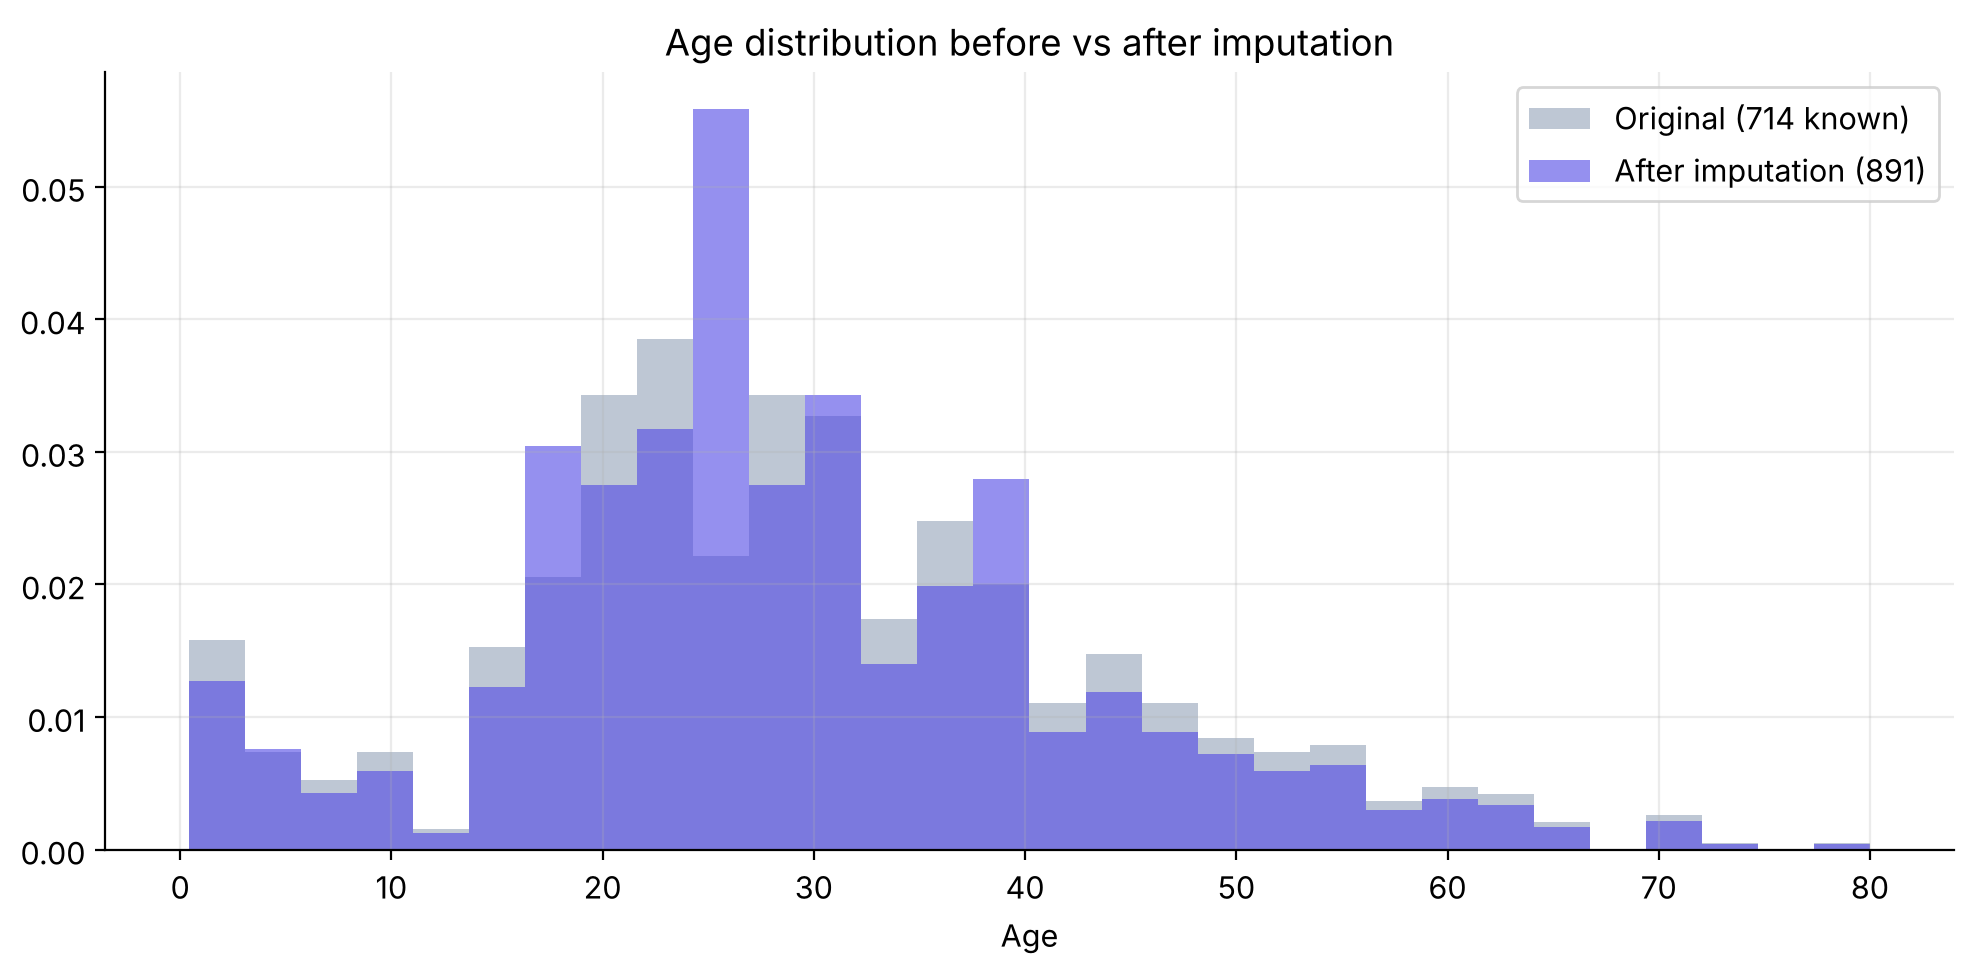

Mean   : 29.70 -> 29.14
Median : 28.00 -> 26.00
Std    : 14.53 -> 13.49


In [11]:
# Did imputation distort the Age distribution?
fig, ax = plt.subplots()
ax.hist(age_before.dropna(), bins=30, alpha=.6, label="Original (714 known)", color="#94A3B8", density=True)
ax.hist(df["Age"], bins=30, alpha=.6, label="After imputation (891)", color="#4F46E5", density=True)
ax.set_title("Age distribution before vs after imputation"); ax.set_xlabel("Age"); ax.legend()
save_fig("04_age_imputation_check")
print(f"Mean   : {age_before.mean():.2f} -> {df['Age'].mean():.2f}")
print(f"Median : {age_before.median():.2f} -> {df['Age'].median():.2f}")
print(f"Std    : {age_before.std():.2f} -> {df['Age'].std():.2f}")

## Step 3 — Apply the IQR method to detect outliers

**IQR rule:** a value is an outlier if it lies below `Q1 − 1.5·IQR` or above `Q3 + 1.5·IQR`.

It is applied only to **continuous** columns (`Age`, `Fare`). `SibSp`/`Parch` are small discrete counts (for `Parch`, IQR = 0 so the fences collapse and flag every non-zero value) – IQR is the wrong tool for them.

In [12]:
def iqr_fences(s, k=1.5):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

rows = []
for col in ["Age", "Fare"]:
    lo, hi = iqr_fences(df[col])
    n_low, n_high = (df[col] < lo).sum(), (df[col] > hi).sum()
    rows.append({"column": col, "Q1": df[col].quantile(.25), "Q3": df[col].quantile(.75),
                 "lower_fence": lo, "upper_fence": hi, "n_low": n_low, "n_high": n_high,
                 "outlier_%": (n_low + n_high) / len(df) * 100, "skew": df[col].skew()})
outlier_report = pd.DataFrame(rows).set_index("column")
outlier_report

,Q1,Q3,lower_fence,upper_fence,n_low,n_high,outlier_%,skew
column,,,,,,,,
Age,21.00,36.75,-2.62,60.38,0,22,2.47,0.47
Fare,7.91,31.00,-26.72,65.63,0,116,13.02,4.79


/tmp/ipykernel_114/516308614.py:4: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[0, j].boxplot(df[col], vert=False, patch_artist=True, boxprops=dict(facecolor="#C7D2FE"))
/tmp/ipykernel_114/516308614.py:4: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[0, j].boxplot(df[col], vert=False, patch_artist=True, boxprops=dict(facecolor="#C7D2FE"))


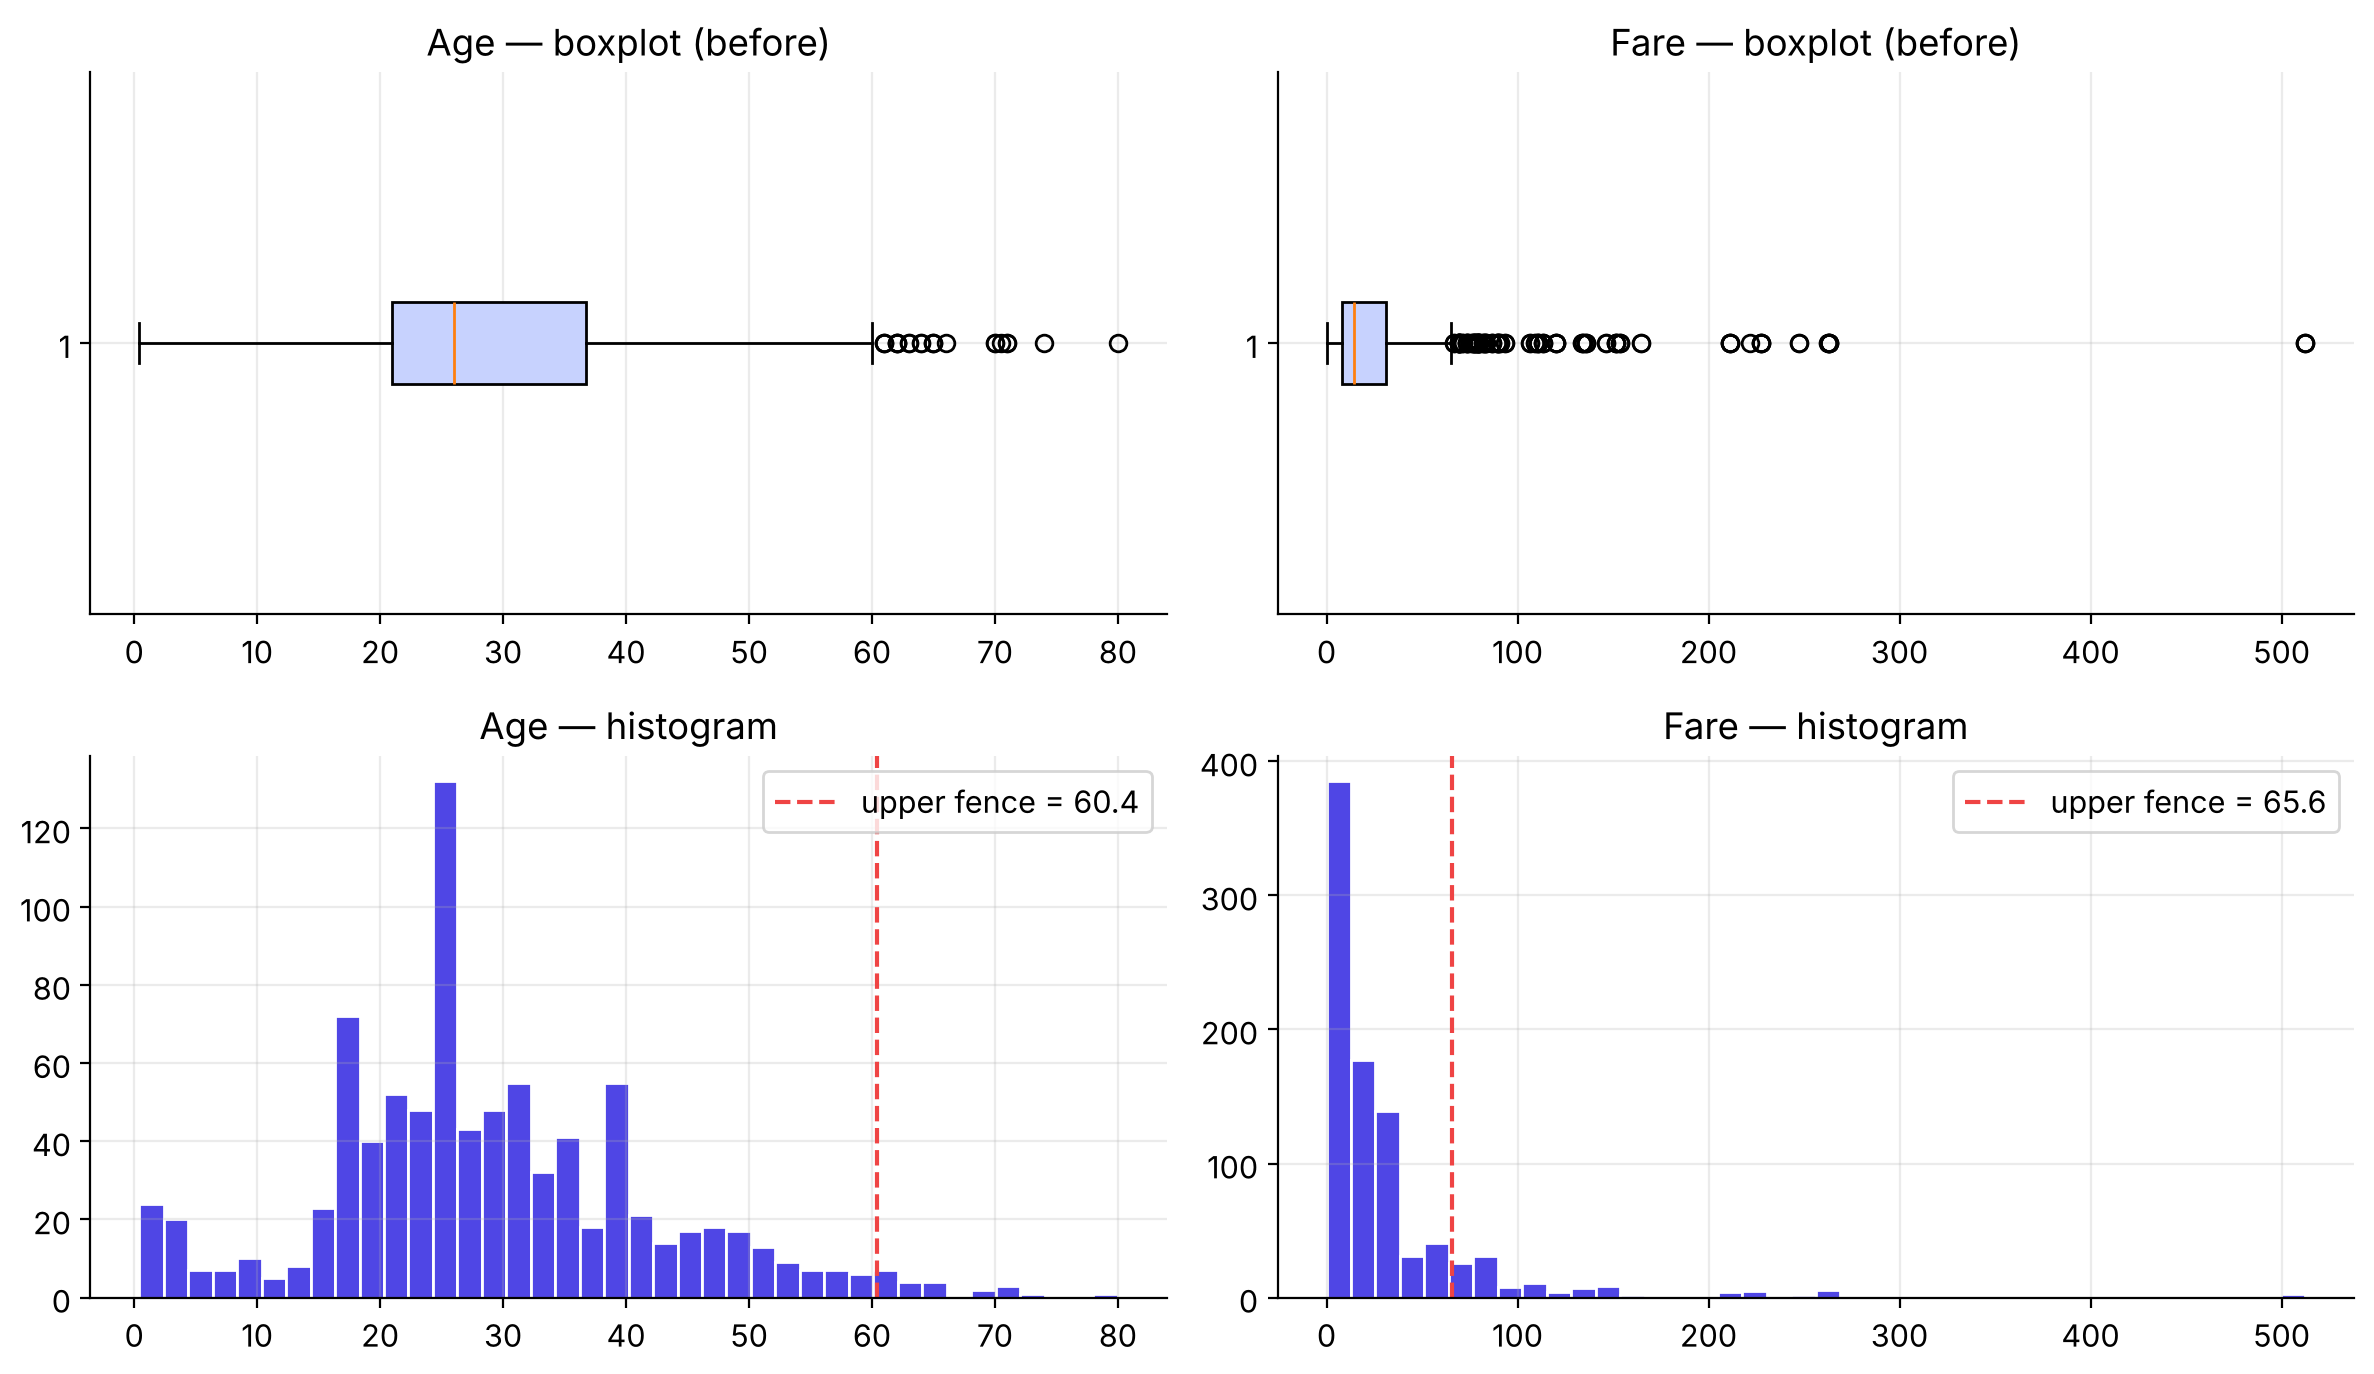

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for j, col in enumerate(["Age", "Fare"]):
    lo, hi = iqr_fences(df[col])
    axes[0, j].boxplot(df[col], vert=False, patch_artist=True, boxprops=dict(facecolor="#C7D2FE"))
    axes[0, j].set_title(f"{col} — boxplot (before)")
    axes[1, j].hist(df[col], bins=40, color="#4F46E5", edgecolor="white")
    axes[1, j].axvline(hi, color="#EF4444", ls="--", label=f"upper fence = {hi:.1f}")
    if lo > df[col].min(): axes[1, j].axvline(lo, color="#EF4444", ls="--")
    axes[1, j].set_title(f"{col} — histogram"); axes[1, j].legend()
save_fig("05_outliers_before")

In [14]:
lo, hi = iqr_fences(df["Fare"])
fare_out = df[df["Fare"] > hi]
print(f"Fare outliers: {len(fare_out)} rows ({len(fare_out)/len(df):.1%})")
print("\nBy passenger class:"); print(fare_out["Pclass"].value_counts().sort_index().to_string())
print(f"\nSurvival rate  outliers: {fare_out['Survived'].mean():.1%}   vs   rest: {df[df['Fare'] <= hi]['Survived'].mean():.1%}")
print(f"Zero-fare rows (possible free tickets / data issue): {(df['Fare'] == 0).sum()}")
print(f"Max fare: {df['Fare'].max():.2f}  (median {df['Fare'].median():.2f})")

Fare outliers: 116 rows (13.0%)

By passenger class:
Pclass
1    104
2      5
3      7

Survival rate  outliers: 68.1%   vs   rest: 33.9%
Zero-fare rows (possible free tickets / data issue): 15
Max fare: 512.33  (median 14.45)


**Reading the result:** `Fare` is extremely right-skewed. About 13% of rows exceed the upper fence and **90% of them are 1st-class** — these are *genuine* expensive tickets, not typing mistakes, and they survived at about twice the average rate. `Age` has only a small number of flagged values (elderly passengers), which are also real.

## Step 4 — Remove or cap outliers

Two options are compared before choosing:

- **Remove** the rows → simple, but deletes ~13% of data and almost only 1st-class, high-survival passengers (introduces **selection bias**).
- **Cap (winsorize)** at the IQR fences → keeps every row and the *ordering* (expensive stays expensive) while limiting the leverage of extreme values.

In [15]:
fare_lo, fare_hi = iqr_fences(df["Fare"])
removed = df[(df["Fare"] >= fare_lo) & (df["Fare"] <= fare_hi)]
capped  = df["Fare"].clip(lower=fare_lo, upper=fare_hi)

comparison = pd.DataFrame({
    "Original":          [len(df),      df["Fare"].mean(), df["Fare"].median(), df["Fare"].std(), df["Fare"].skew(), df["Survived"].mean()],
    "Removed outliers":  [len(removed), removed["Fare"].mean(), removed["Fare"].median(), removed["Fare"].std(), removed["Fare"].skew(), removed["Survived"].mean()],
    "Capped (chosen)":   [len(df),      capped.mean(), capped.median(), capped.std(), capped.skew(), df["Survived"].mean()],
}, index=["rows", "mean", "median", "std", "skew", "survival rate"])
comparison

,Original,Removed outliers,Capped (chosen)
rows,891.00,775.00,891.00
mean,32.20,17.82,24.05
median,14.45,13.00,14.45
std,49.69,13.58,20.48
skew,4.79,1.43,1.08
survival rate,0.38,0.34,0.38


In [16]:
# ---- Apply the chosen strategy: cap Age and Fare at their IQR fences ----
df_clean = df.copy()
before = df_clean[["Age", "Fare"]].copy()

for col in ["Age", "Fare"]:
    lo, hi = iqr_fences(df_clean[col])
    n = ((df_clean[col] < lo) | (df_clean[col] > hi)).sum()
    df_clean[col] = df_clean[col].clip(lower=lo, upper=hi)
    print(f"{col:5s}: capped {n:3d} values to [{max(lo, before[col].min()):.2f}, {hi:.2f}]")

Age  : capped  22 values to [0.42, 60.38]
Fare : capped 116 values to [0.00, 65.63]


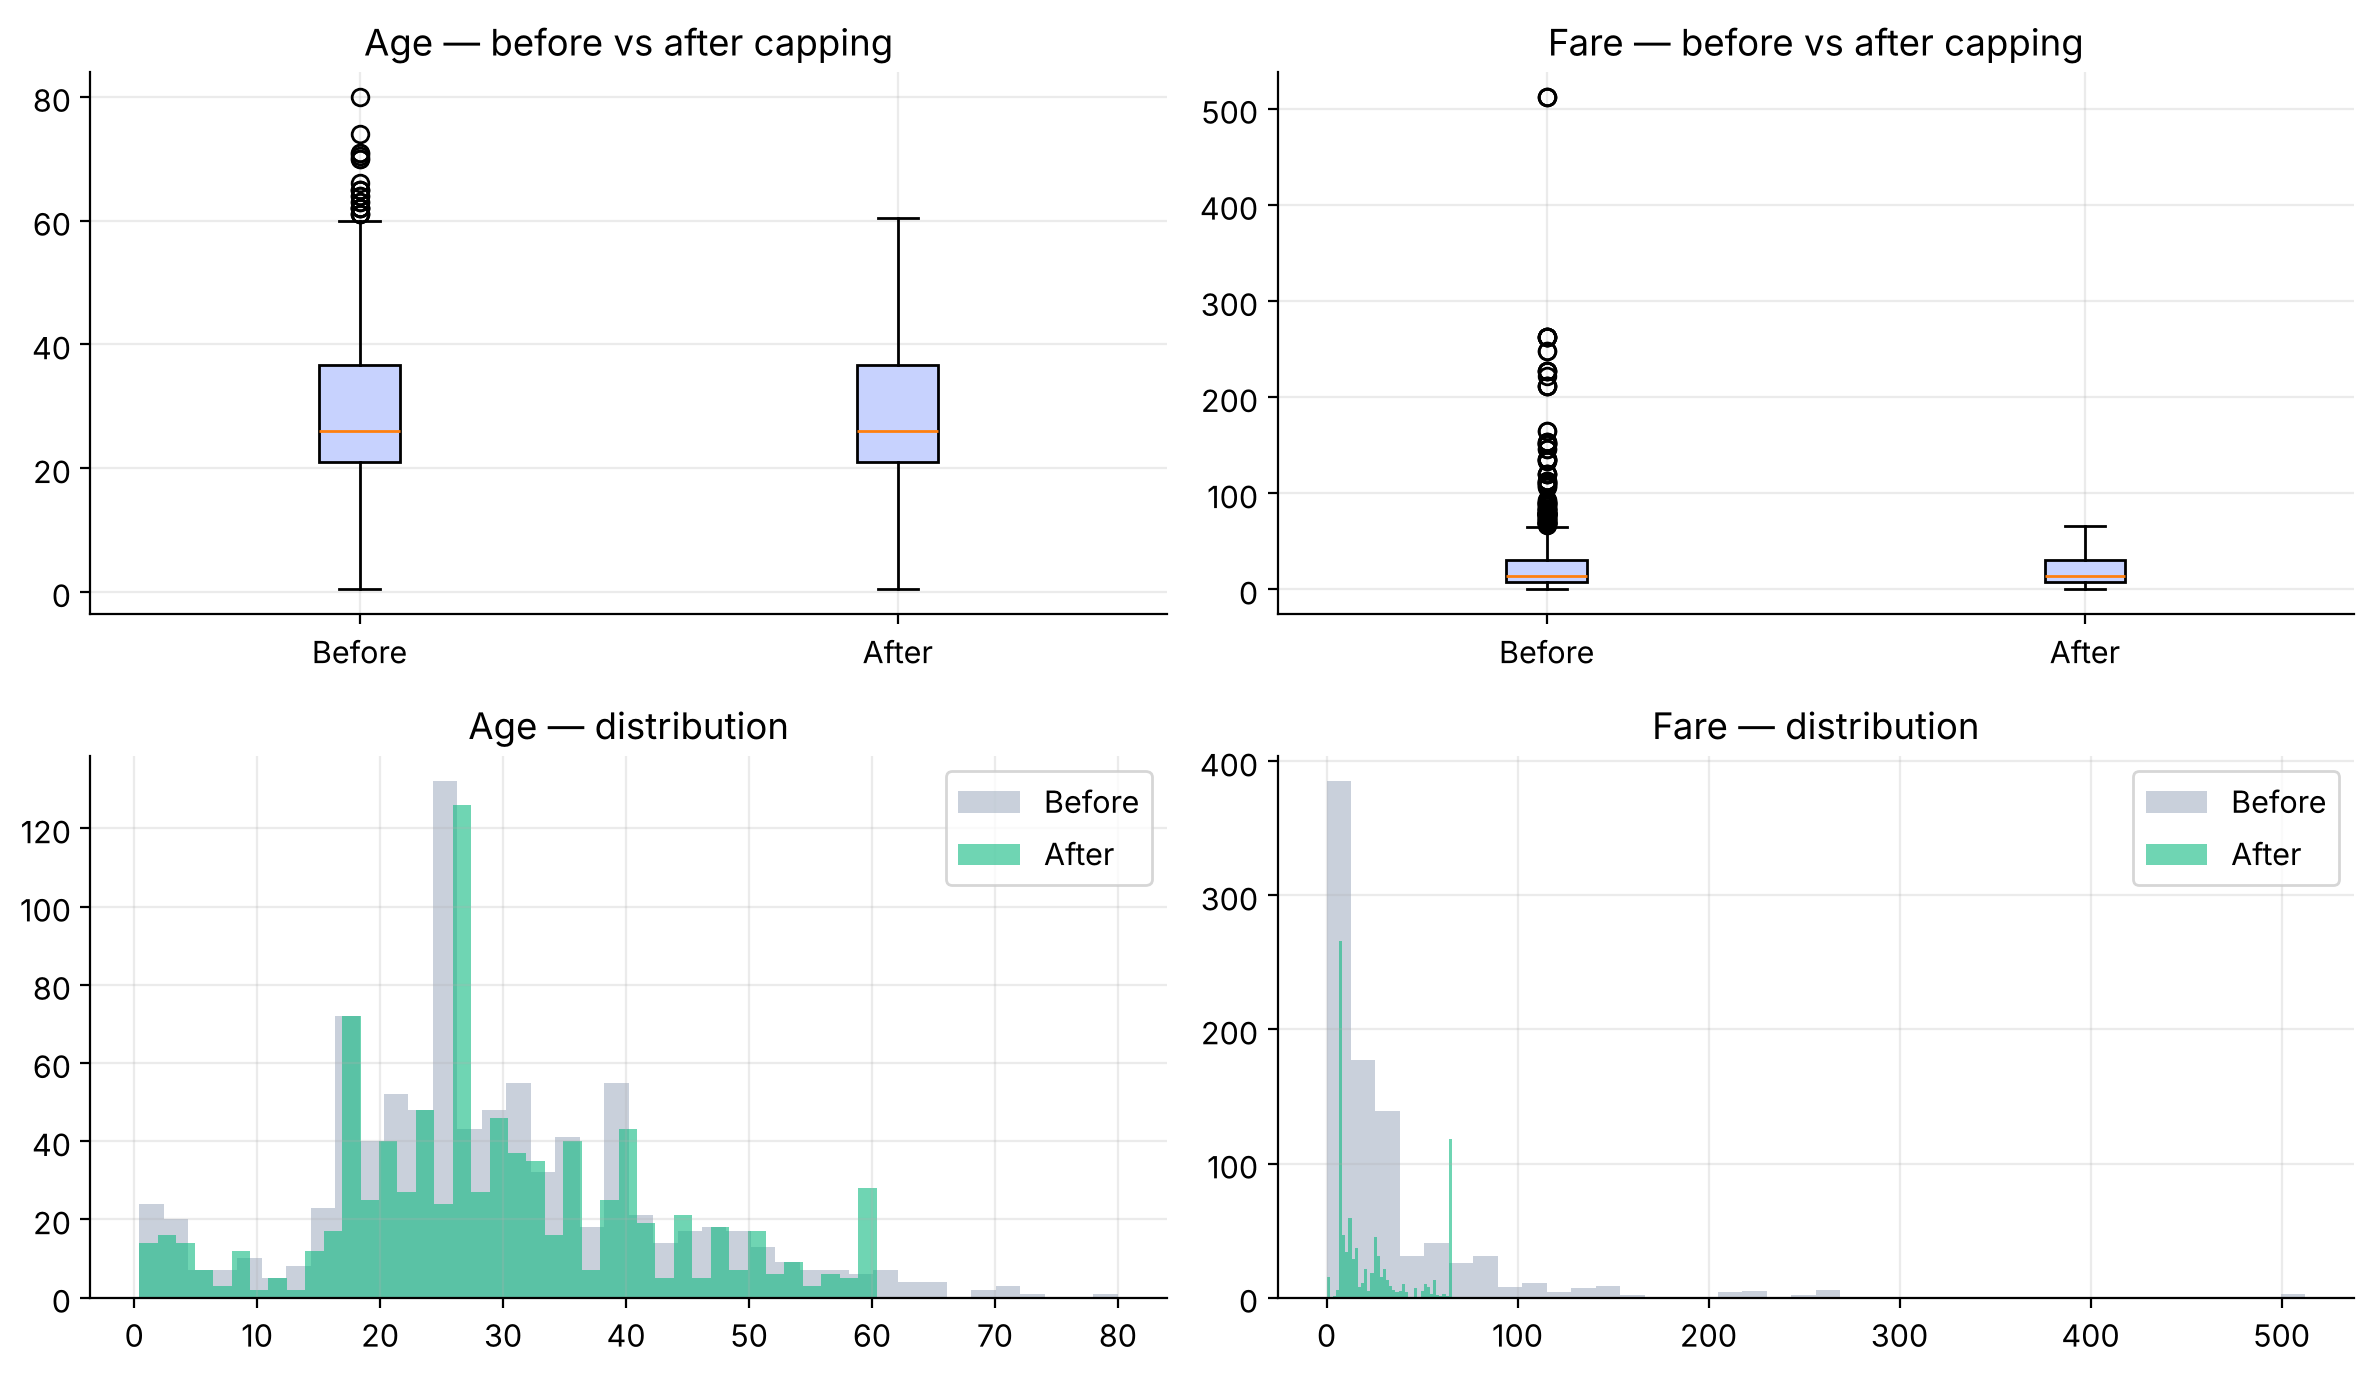

Fare skew: 4.79 -> 1.08
Age  skew: 0.47 -> 0.30


In [17]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for j, col in enumerate(["Age", "Fare"]):
    axes[0, j].boxplot([before[col], df_clean[col]], tick_labels=["Before", "After"], patch_artist=True,
                       boxprops=dict(facecolor="#C7D2FE"))
    axes[0, j].set_title(f"{col} — before vs after capping")
    axes[1, j].hist(before[col], bins=40, alpha=.5, color="#94A3B8", label="Before")
    axes[1, j].hist(df_clean[col], bins=40, alpha=.6, color="#10B981", label="After")
    axes[1, j].legend(); axes[1, j].set_title(f"{col} — distribution")
save_fig("06_outliers_after")
print(f"Fare skew: {before['Fare'].skew():.2f} -> {df_clean['Fare'].skew():.2f}")
print(f"Age  skew: {before['Age'].skew():.2f} -> {df_clean['Age'].skew():.2f}")

### Decision & justification
- **Fare → capped** at the IQR upper fence (≈ 65.63). All 891 rows kept; skew drops from ~4.8 to ~1.1.
- **Age → capped** at the upper fence (≈ 60.4). It only touches ~2.5% of rows and the lower fence (< 0) is not binding. If you need exact ages of the oldest passengers, skip this line — they are real values.
- **Zero fares (15 rows)** are left unchanged and flagged: they are plausible (crew / complimentary tickets), not statistical outliers.
- Alternative worth trying for modelling: a `log1p(Fare)` transform instead of capping.

## Step 5 — Validate & export the cleaned data

In [18]:
# ---- Validation checks ----
assert df_clean.isna().sum().sum() == 0,           "nulls remain"
assert df_clean.duplicated().sum() == 0,           "duplicates remain"
assert len(df_clean) == len(raw),                  "rows were lost"
assert df_clean["Age"].between(0, 120).all(),      "impossible ages"
assert (df_clean["Fare"] >= 0).all(),              "negative fares"
print("✅ All validation checks passed")
print(f"Shape: {raw.shape} -> {df_clean.shape}")

✅ All validation checks passed
Shape: (891, 12) -> (891, 13)


In [19]:
cleaned_path = OUT_DIR / "titanic_cleaned.csv"
df_clean.to_csv(cleaned_path, index=False)

# Cleaning log: what changed and why (handy for README / reports)
log = pd.DataFrame([
    ["Age",      "177 missing (19.9%)", "Imputed: median of Title x Pclass group"],
    ["Cabin",    "687 missing (77.1%)", "Dropped column; added Has_Cabin flag"],
    ["Embarked", "2 missing (0.2%)",    "Imputed: mode (S)"],
    ["Age",      "outliers > upper IQR fence", "Capped at upper fence"],
    ["Fare",     "116 outliers > upper IQR fence", "Capped at upper fence"],
    ["Title",    "new feature",         "Extracted from Name; rare titles grouped"],
], columns=["column", "issue", "action"])
log.to_csv(OUT_DIR / "cleaning_log.csv", index=False)
outlier_report.to_csv(OUT_DIR / "outlier_report.csv")

print("Saved:", *sorted(p.name for p in OUT_DIR.glob("*.csv")), sep="\n  - ")
log

Saved:
  - cleaning_log.csv
  - outlier_report.csv
  - titanic_cleaned.csv


,column,issue,action
0,Age,177 missing (19.9%),Imputed: median of Title x Pclass group
1,Cabin,687 missing (77.1%),Dropped column; added Has_Cabin flag
2,Embarked,2 missing (0.2%),Imputed: mode (S)
3,Age,outliers > upper IQR fence,Capped at upper fence
4,Fare,116 outliers > upper IQR fence,Capped at upper fence
5,Title,new feature,Extracted from Name; rare titles grouped


In [20]:
# Reload to confirm the exported file is readable and clean
check = pd.read_csv(cleaned_path)
print(check.shape, "| nulls:", int(check.isna().sum().sum()))
check.head()

(891, 13) | nulls: 0


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked,Has_Cabin,Title
0,1,0,3,"Braund, Mr. Owen Harris",male,22.00,1,0,A/5 21171,7.25,S,0,Mr
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.00,1,0,PC 17599,65.63,C,1,Mrs
2,3,1,3,"Heikkinen, Miss. Laina",female,26.00,0,0,STON/O2. 3101282,7.92,S,0,Miss
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.00,1,0,113803,53.10,S,1,Mrs
4,5,0,3,"Allen, Mr. William Henry",male,35.00,0,0,373450,8.05,S,0,Mr


## ✅ Summary
| | Before | After |
|---|---|---|
| Rows | 891 | 891 (none lost) |
| Missing cells | 866 | 0 |
| Fare skew | ~4.8 | ~1.1 |
| Columns | 12 | 13 (`Cabin` → `Has_Cabin`, + `Title`) |

**Next steps:** encode categoricals (`Sex`, `Embarked`, `Title`), try `log1p(Fare)`, and train a survival classifier on `titanic_cleaned.csv`.